In [3]:
from PIL import Image
import glob

In [10]:
image_list= []
for file_name in glob.glob("Vehicules/*.jpg"):
    image=Image.open(file_name)
    image_list.append(image)

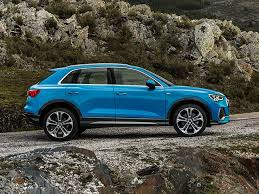

In [11]:
display(image_list[0])

In [ ]:
import chromadb
from chromadb.utils.data_loaders import ImageLoader
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction

In [17]:
chromadb_client = chromadb.PersistentClient(path="vehicules-store-vdb")
image_loader = ImageLoader()
image_embedding_model = OpenCLIPEmbeddingFunction()
chromadb_vdb = chromadb_client.get_or_create_collection(name="vehicules" , data_loader= image_loader , embedding_function = image_embedding_model )


c:\Users\loq\Desktop\App-MultoModal-RAG\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\loq\.cache\huggingface\hub\models--laion--CLIP-ViT-B-32-laion2B-s34B-b79K. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [22]:
import os
images_ids = []
images_uris = []
images_folder = "Vehicules"
for index, image_name in enumerate(sorted(os.listdir(images_folder))):
    if(image_name.endswith(".jpg")):
        image_path = os.path.join(images_folder, image_name)
        images_ids.append(str(index))
        images_uris.append(image_path)

In [23]:
print(images_ids[0:5])
print(images_uris[0:5])



['0', '1', '2', '3', '4']
['Vehicules\\1234.jpg', 'Vehicules\\1236.jpg', 'Vehicules\\1237.jpg', 'Vehicules\\213.jpg', 'Vehicules\\215.jpg']


In [25]:
chromadb_vdb.add(ids=images_ids, uris=images_uris)

In [28]:
chromadb_vdb.count()

21

In [29]:
results = chromadb_vdb.query(query_texts=['give me red cars'] , n_results=4, include=['uris','distances'])

In [30]:
results

{'ids': [['8', '10', '2', '15']],
 'embeddings': None,
 'documents': None,
 'uris': [['Vehicules\\58.jpg',
   'Vehicules\\79.jpg',
   'Vehicules\\1237.jpg',
   'Vehicules\\87.jpg']],
 'included': ['uris', 'distances'],
 'data': None,
 'metadatas': None,
 'distances': [[0.7869841456413269,
   0.7962535619735718,
   0.8096300959587097,
   0.8168482780456543]]}

In [ ]:
display()